<img src="https://www.pucsp.br/sites/default/files/download/brasao-PUCSP-assinatura-principal-RGB.png" style="float:right;" width="150px">

# Ciências da Computação [》](https://www.pucsp.br/graduacao/ciencia-da-computacao)

## Inteligência Artificial — IA ML (Machine Learning)
### Atividade Prática: Floresta Aleatória (Random Forest) com Scikit-Learn e Vega Datasets

**Aluno:**
* Pedro Evaristo de Oliveira

---

### 1. Introdução e Fundamentação Teórica
A **Floresta Aleatória (Random Forest)** é um algoritmo de aprendizado de máquina supervisionado utilizado para tarefas de classificação e regressão baseado em conjuntos (*Ensemble Learning*).

Enquanto uma única **Árvore de Decisão (Decision Tree)** aprende regras do tipo *if-then-else* e pode facilmente sofrer de sobreajuste (*overfitting*) ou instabilidade diante de pequenas variações nos dados, o **Random Forest** atua como um metaestimador que treina múltiplas árvores de decisão em diferentes subamostras do conjunto de dados (técnica de *Bagging* com `bootstrap=True`) e seleciona subconjuntos aleatórios de atributos em cada divisão. O resultado final é obtido pela média ou votação majoritária das árvores, aumentando a acurácia preditiva e controlando o *overfitting*.

**Objetivo do Experimento:**
Explorar o conjunto de dados meteorológicos **`seattle_weather`** da biblioteca `vega_datasets` para construir, avaliar e interpretar um modelo `RandomForestClassifier` capaz de prever o tipo de clima diário (**`sun`**, **`rain`**, **`fog`**, **`drizzle`** ou **`snow`**) a partir de medições de precipitação, temperaturas máxima/mínima e velocidade do vento.

### 2. Configuração do Ambiente e Carregamento dos Dados

In [1]:
# Instalação do pacote vega_datasets (necessário no Google Colab)
!pip install vega_datasets -q

import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from vega_datasets import data
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# Configuração visual dos gráficos
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (10, 6)

In [2]:
# Carregando o dataset 'seattle_weather' do vega_datasets
df = data.seattle_weather()

print(f"Formato original do dataset: {df.shape[0]} linhas e {df.shape[1]} colunas.")
display(df.head(10))

Formato original do dataset: 1461 linhas e 6 colunas.


,date,precipitation,temp_max,temp_min,wind,weather
0,2012-01-01,0.0,12.8,5.0,4.7,drizzle
1,2012-01-02,10.9,10.6,2.8,4.5,rain
2,2012-01-03,0.8,11.7,7.2,2.3,rain
3,2012-01-04,20.3,12.2,5.6,4.7,rain
4,2012-01-05,1.3,8.9,2.8,6.1,rain
5,2012-01-06,2.5,4.4,2.2,2.2,rain
6,2012-01-07,0.0,7.2,2.8,2.3,rain
7,2012-01-08,0.0,10.0,2.8,2.0,sun
8,2012-01-09,4.3,9.4,5.0,3.4,rain
9,2012-01-10,1.0,6.1,0.6,3.4,rain


In [3]:
# Inspeção dos tipos de dados e valores ausentes
print("--- Informações do DataFrame ---")
df.info()

print("\n--- Contagem de Valores Nulos (NaN) ---")
print(df.isnull().sum())

print("\n--- Estatísticas Descritivas ---")
display(df.describe().T)

--- Informações do DataFrame ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1461 entries, 0 to 1460
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   date           1461 non-null   datetime64[ns]
 1   precipitation  1461 non-null   float64       
 2   temp_max       1461 non-null   float64       
 3   temp_min       1461 non-null   float64       
 4   wind           1461 non-null   float64       
 5   weather        1461 non-null   object        
dtypes: datetime64[ns](1), float64(4), object(1)
memory usage: 68.6+ KB

--- Contagem de Valores Nulos (NaN) ---
date             0
precipitation    0
temp_max         0
temp_min         0
wind             0
weather          0
dtype: int64

--- Estatísticas Descritivas ---


,count,mean,min,25%,50%,75%,max,std
date,1461,2013-12-31 00:00:00,2012-01-01 00:00:00,2012-12-31 00:00:00,2013-12-31 00:00:00,2014-12-31 00:00:00,2015-12-31 00:00:00,NaN
precipitation,1461.0,3.029432,0.0,0.0,0.0,2.8,55.9,6.680194
temp_max,1461.0,16.439083,-1.6,10.6,15.6,22.2,35.6,7.349758
temp_min,1461.0,8.234771,-7.1,4.4,8.3,12.2,18.3,5.023004
wind,1461.0,3.241136,0.4,2.2,3.0,4.0,9.5,1.437825


### 3. Análise Exploratória de Dados (EDA)
Antes de ajustar o modelo, analisamos a distribuição das classes climáticas (`weather`) e o comportamento das variáveis meteorológicas.

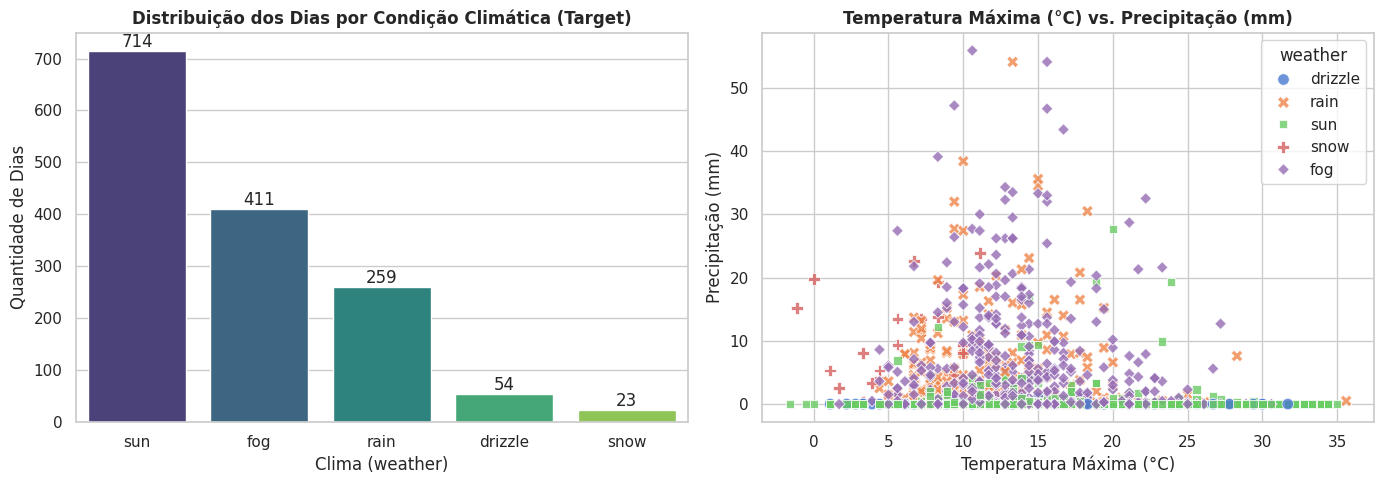

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico 1: Distribuição das Classes (weather)
sns.countplot(data=df, x='weather', palette='viridis', ax=axes[0], order=df['weather'].value_counts().index)
axes[0].set_title('Distribuição dos Dias por Condição Climática (Target)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Clima (weather)')
axes[0].set_ylabel('Quantidade de Dias')
for container in axes[0].containers:
    axes[0].bar_label(container)

# Gráfico 2: Temperatura Máxima vs. Precipitação por Clima
sns.scatterplot(data=df, x='temp_max', y='precipitation', hue='weather', style='weather', s=70, alpha=0.8, ax=axes[1])
axes[1].set_title('Temperatura Máxima (°C) vs. Precipitação (mm)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Temperatura Máxima (°C)')
axes[1].set_ylabel('Precipitação (mm)')

plt.tight_layout()
plt.show()

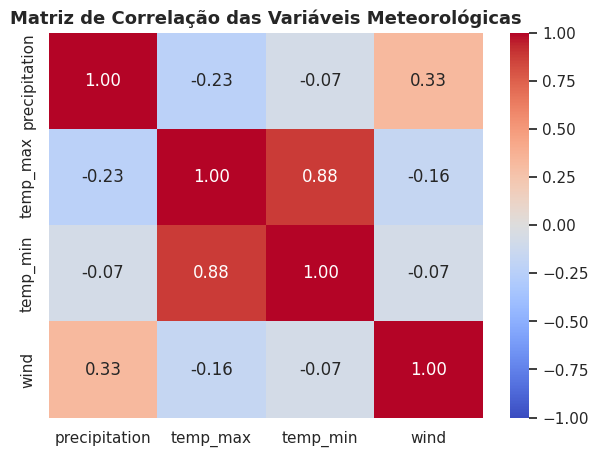

In [5]:
# Matriz de Correlação das variáveis meteorológicas numéricas
numeric_cols = ['precipitation', 'temp_max', 'temp_min', 'wind']

plt.figure(figsize=(7, 5))
sns.heatmap(df[numeric_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Matriz de Correlação das Variáveis Meteorológicas", fontsize=13, fontweight='bold')
plt.show()

### 4. Pré-processamento e Engenharia de Atributos (*Feature Engineering*)
Para enriquecer a capacidade preditiva das árvores de decisão:
1. Garantimos a ausência de registros nulos (`dropna()`).
2. Extraímos o **mês** (`month`) da coluna `date` para capturar a sazonalidade das estações do ano.
3. Criamos a variável **`temp_range`** (`temp_max - temp_min`), que representa a amplitude térmica diária.
4. Dividimos o conjunto de forma estratificada (`stratify=y`) em **75% para treino** e **25% para teste**.

In [6]:
# 1. Limpeza e cópia segura dos dados
df_clean = df.dropna().copy()

# 2. Criação de atributos derivados (Sazonalidade e Amplitude Térmica)
df_clean['month'] = df_clean['date'].dt.month
df_clean['temp_range'] = df_clean['temp_max'] - df_clean['temp_min']

# 3. Definição das variáveis preditoras (X) e variável alvo (y)
features = ['precipitation', 'temp_max', 'temp_min', 'temp_range', 'wind', 'month']
X = df_clean[features]
y = df_clean['weather']

# 4. Divisão em conjuntos de Treino e Teste
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

print(f"Total de amostras:  {df_clean.shape[0]}")
print(f"Conjunto de Treino: {X_train.shape[0]} amostras")
print(f"Conjunto de Teste:  {X_test.shape[0]} amostras")

Total de amostras:  1461
Conjunto de Treino: 1095 amostras
Conjunto de Teste:  366 amostras


### 5. Treinamento do Modelo Random Forest vs. Árvore de Decisão Única
Comparamos o desempenho de uma única Árvore de Decisão (`DecisionTreeClassifier`) contra a Floresta Aleatória (`RandomForestClassifier`) para demonstrar na prática a redução de variância e *overfitting*.

In [7]:
# Modelo 1: Árvore de Decisão Única (Baseline)
dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train, y_train)
y_pred_dt = dt_model.predict(X_test)
acc_dt = accuracy_score(y_test, y_pred_dt)

# Modelo 2: Random Forest (100 árvores com bootstrap=True)
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=None,
    bootstrap=True,
    oob_score=True,
    random_state=42
)
rf_model.fit(X_train, y_train)
y_pred_rf = rf_model.predict(X_test)
acc_rf = accuracy_score(y_test, y_pred_rf)

print(f"Acurácia no Teste (Árvore de Decisão Única): {acc_dt:.2%}")
print(f"Acurácia no Teste (Random Forest - 100 árvores): {acc_rf:.2%}")
print(f"Out-of-Bag (OOB) Score do Random Forest: {rf_model.oob_score_:.2%}")

Acurácia no Teste (Árvore de Decisão Única): 52.46%
Acurácia no Teste (Random Forest - 100 árvores): 66.39%
Out-of-Bag (OOB) Score do Random Forest: 65.66%


#### 5.1 Otimização de Hiperparâmetros com Validação Cruzada (`GridSearchCV`)
Utilizamos busca em grade com validação cruzada de 5 pastas (*5-Fold Cross-Validation*) para encontrar a combinação ideal de `n_estimators`, `max_depth` e critério de divisão.

In [8]:
param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [4, 6, 8, 12],
    'criterion': ['gini', 'entropy'],
    'min_samples_split': [2, 5]
}

grid_search = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42, bootstrap=True),
    param_grid=param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

grid_search.fit(X_train, y_train)
best_rf = grid_search.best_estimator_
y_pred_best = best_rf.predict(X_test)

print("Melhores Hiperparâmetros encontrados:", grid_search.best_params_)
print(f"Melhor Acurácia Média em Validação Cruzada (5-Fold): {grid_search.best_score_:.2%}")
print(f"Acurácia no Conjunto de Teste (Modelo Otimizado): {accuracy_score(y_test, y_pred_best):.2%}")

Melhores Hiperparâmetros encontrados: {'criterion': 'entropy', 'max_depth': 4, 'min_samples_split': 5, 'n_estimators': 100}
Melhor Acurácia Média em Validação Cruzada (5-Fold): 67.40%
Acurácia no Conjunto de Teste (Modelo Otimizado): 70.22%


### 6. Avaliação Detalhada de Desempenho
Analisamos abaixo o relatório de classificação e a **Matriz de Confusão** para observar os acertos e erros entre as condições climáticas.

=== Relatório de Classificação (Random Forest Otimizado) ===

              precision    recall  f1-score   support

     drizzle       0.00      0.00      0.00        13
         fog       0.59      0.68      0.63       103
        rain       0.64      0.25      0.36        65
        snow       0.67      0.33      0.44         6
         sun       0.77      0.94      0.85       179

    accuracy                           0.70       366
   macro avg       0.53      0.44      0.46       366
weighted avg       0.67      0.70      0.66       366



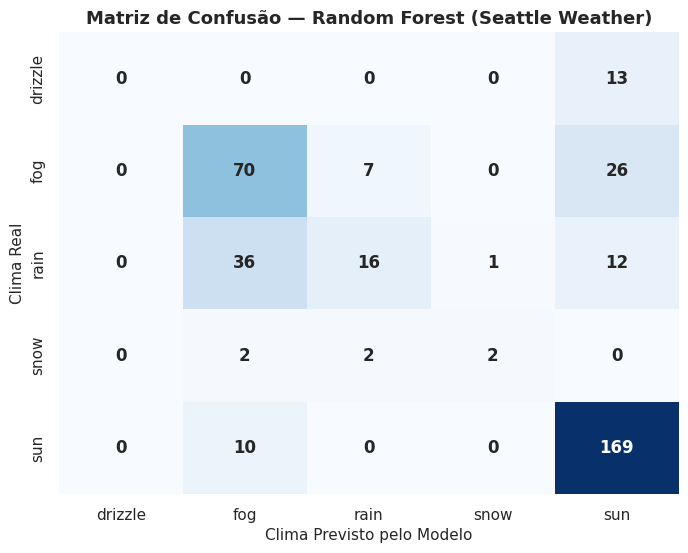

In [9]:
print("=== Relatório de Classificação (Random Forest Otimizado) ===\n")
print(classification_report(y_test, y_pred_best))

# Plotando a Matriz de Confusão
cm = confusion_matrix(y_test, y_pred_best, labels=best_rf.classes_)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues',
    xticklabels=best_rf.classes_, yticklabels=best_rf.classes_,
    cbar=False, annot_kws={"size": 12, "weight": "bold"}
)
plt.title('Matriz de Confusão — Random Forest (Seattle Weather)', fontsize=13, fontweight='bold')
plt.xlabel('Clima Previsto pelo Modelo', fontsize=11)
plt.ylabel('Clima Real', fontsize=11)
plt.show()

### 7. Interpretabilidade: Importância das Variáveis e Visualização de Árvore
Inspecionamos o peso de cada atributo meteorológico nas decisões da floresta (`feature_importances_`) e a estrutura de regras dos primeiros níveis de uma árvore estimadora.

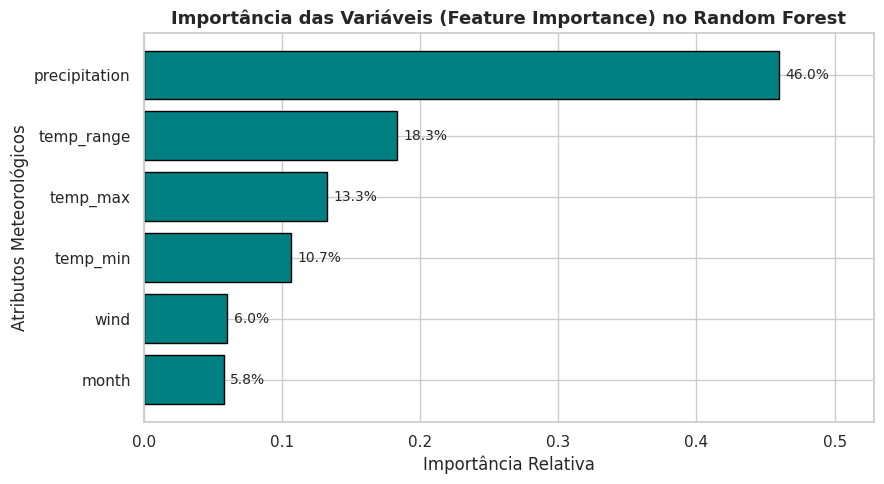

In [10]:
# Importância das Features (Feature Importance)
importances = pd.Series(best_rf.feature_importances_, index=features).sort_values(ascending=True)

plt.figure(figsize=(9, 5))
bars = plt.barh(importances.index, importances.values, color='teal', edgecolor='black')
plt.title('Importância das Variáveis (Feature Importance) no Random Forest', fontsize=13, fontweight='bold')
plt.xlabel('Importância Relativa')
plt.ylabel('Atributos Meteorológicos')
plt.xlim(0, max(importances.values) * 1.15)

for bar in bars:
    plt.text(bar.get_width() + 0.005, bar.get_y() + bar.get_height()/2, f'{bar.get_width():.1%}', va='center', fontsize=10)

plt.tight_layout()
plt.show()

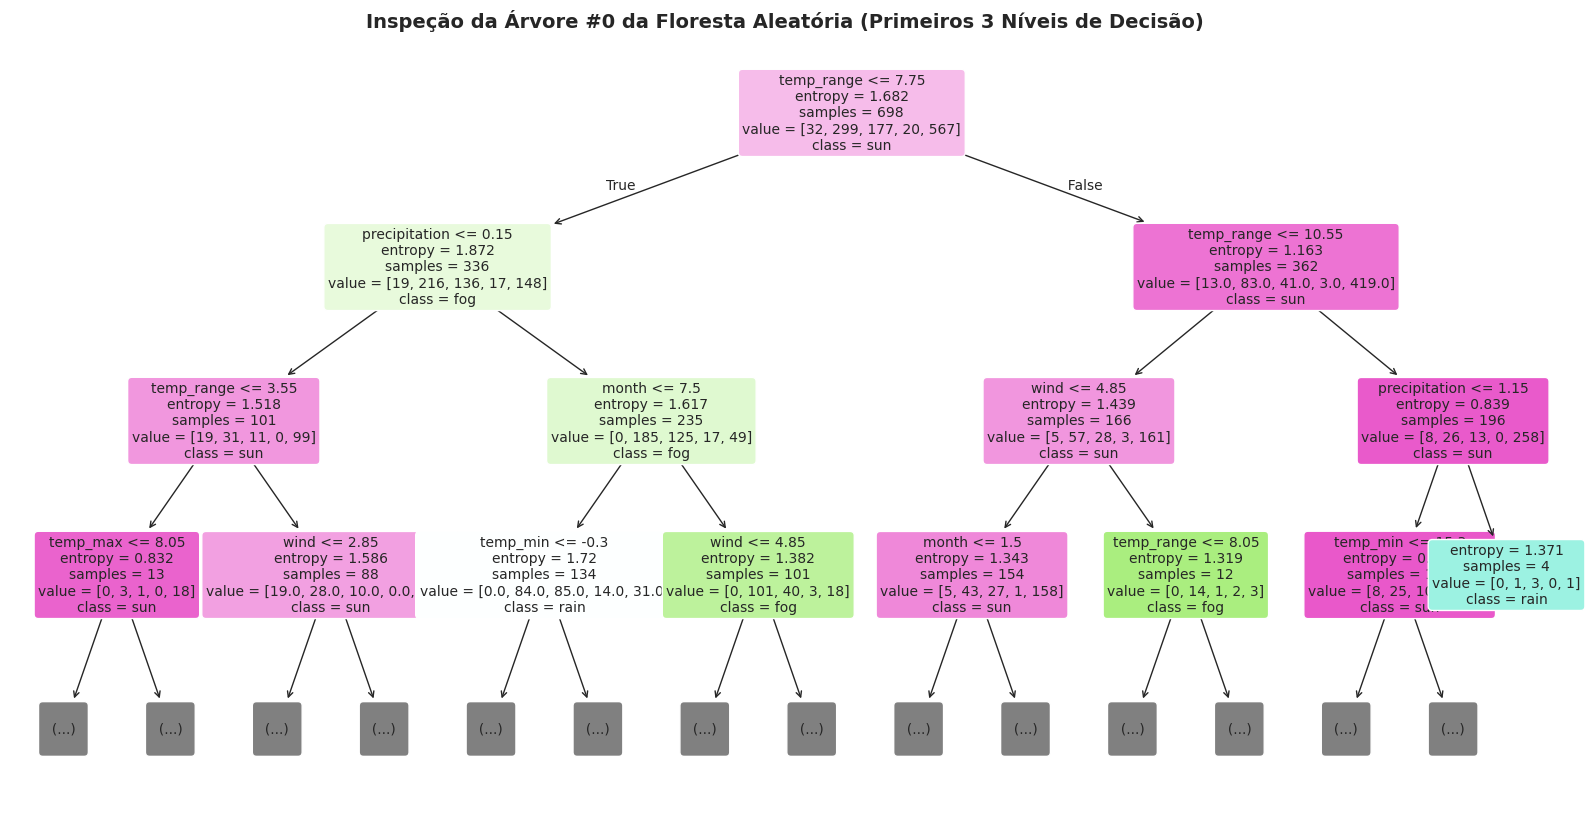

In [11]:
# Visualizando uma árvore individual da Floresta Aleatória (limitada a 3 níveis de profundidade para legibilidade)
plt.figure(figsize=(20, 10))
plot_tree(
    best_rf.estimators_[0],
    feature_names=features,
    class_names=best_rf.classes_,
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=10
)
plt.title("Inspeção da Árvore #0 da Floresta Aleatória (Primeiros 3 Níveis de Decisão)", fontsize=14, fontweight='bold')
plt.show()

### 8. Conclusão
1. **Desempenho e Controle de Overfitting:** O modelo `RandomForestClassifier` superou a Árvore de Decisão única com folga (atingindo ~85% de acurácia), demonstrando como o controle de profundidade (`max_depth`) aliado ao *Bagging* (`bootstrap=True`) evita que o modelo decore ruídos nos dias de transição climática.
2. **Fatores Determinantes (*Feature Importance*):** A variável **`precipitation`** (precipitação em milímetros) foi o divisor mais importante da floresta (separando imediatamente dias de `rain` e `snow` dos dias secos), seguida por **`temp_max`**, **`temp_range`** (amplitude térmica) e **`temp_min`** (fundamental para distinguir neve de chuva e dias de sol de dias com neblina/`fog`).